# Gaussian toy: sync vs no sync

Generate the original Gaussian-bump experiment in memory, assemble AnnData, fit T,
and inspect its performance before training the two vector fields. Data and T are
created in this run. The flow uses the supplied BalancedSync parameters.

In [1]:
from pathlib import Path
import sys
import uuid

example_dir = next(parent / "examples" for parent in (Path.cwd(), *Path.cwd().parents)
                   if (parent / "examples" / "gaussian_map.py").is_file())
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import anndata as ad
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import coati as ct
from gaussian_map import fit_bump_map, evaluate_bump_map, plot_map_training, plot_map_performance
from gaussian_comparison import make_shared_initial_checkpoint, plot_gaussian_sync, plot_bump_height, compare_gaussian_runs

%matplotlib inline
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
run_dir = Path("outputs") / ("gaussian-fresh-" + uuid.uuid4().hex[:8])
run_dir.mkdir(parents=True)
print("Result directory:", run_dir)

Result directory: outputs/gaussian-fresh-182a53a9


## Generate the observations

Use rejection sampling with seed 2026 and isotropic covariance matrices: 1000 initial
points centered at (0.30, 0.30), followed by two groups of 1000 centered at
(0.56, 0.82) and (0.83, 0.56). Observed secondary coordinates have z = 0.
The separate 7000 support pairs describe the bump with center (0.5, 0.5),
width 0.08 and amplitude 1.

In [2]:
data_seed, n_initial = 2026, 1000
centers = [np.array([.30, .30]), np.array([.56, .82]), np.array([.83, .56])]
covariances = [.004 * np.eye(2), .003 * np.eye(2), .003 * np.eye(2)]
rng = np.random.default_rng(data_seed)
clouds = []
for center, covariance in zip(centers, covariances):
    chunks, remaining = [], n_initial
    while remaining:
        batch = rng.multivariate_normal(center, covariance, size=max(remaining * 2, 256))
        valid = batch[(batch >= 0.).all(axis=1) & (batch <= 1.).all(axis=1)]
        if not len(valid):
            continue
        chunks.append(valid[:remaining])
        remaining -= min(remaining, len(valid))
    clouds.append(np.concatenate(chunks).astype(np.float32))
time0, time1 = clouds[0], np.concatenate(clouds[1:])

# The original support generation starts a separate RNG with the same seed.
rng_support = np.random.default_rng(data_seed)
uniform = rng_support.uniform(.02, .98, size=(4000, 2)).astype(np.float32)
chunks, remaining = [], 3000
while remaining:
    batch = rng_support.normal(loc=np.array([.5, .5], dtype=np.float32), scale=.13,
                               size=(max(remaining * 2, 256), 2))
    valid = batch[(batch >= 0.).all(axis=1) & (batch <= 1.).all(axis=1)]
    if not len(valid):
        continue
    take = min(remaining, len(valid))
    chunks.append(valid[:take])
    remaining -= take
central = np.concatenate(chunks).astype(np.float32)
support2d = np.concatenate([uniform, central]).astype(np.float32)
squared_radius = np.sum((support2d - np.array([.5, .5], dtype=np.float32)) ** 2, axis=1)
height = np.exp(-squared_radius / (2. * .08 * .08)).astype(np.float32)
support3d = np.column_stack([support2d, height]).astype(np.float32)
print("Primary snapshots:", time0.shape, time1.shape)
print("Map support:", support2d.shape, support3d.shape)

Primary snapshots: (1000, 2) (2000, 2)
Map support: (7000, 2) (7000, 3)


## Assemble AnnData

`cells` contains the observed snapshots with aligned primary and secondary rows,
`time`, `celltype` and unique `barcode` fields. `map_pairs` adds the generated
support for fitting T. Support points have no biological observation time and
are used only for T; they are excluded from vector-field training.

In [3]:
primary = np.concatenate([time0, time1])
secondary = np.column_stack([primary, np.zeros(len(primary), dtype=np.float32)])
barcodes = pd.Index([f"toy-{i:05d}" for i in range(len(primary))])
labels = np.repeat(["Initial", "Terminal A", "Terminal B"], [len(time0), len(time1) // 2, len(time1) // 2])
cells = ad.AnnData(primary.copy(), obs=pd.DataFrame({
    "time": np.repeat([0., 1.], [len(time0), len(time1)]),
    "celltype": pd.Categorical(labels), "barcode": barcodes.to_numpy(),
}, index=barcodes))
cells.obsm["X_latent"] = primary.copy()
cells.obsm["X_secondary"] = secondary.copy()
cells = ct.prepare_anndata(cells, use_rep="X_latent", secondary_key="X_secondary", warn=False)

map_ids = pd.Index([*barcodes, *[f"support-{i:05d}" for i in range(len(support2d))]])
map_pairs = ad.AnnData(np.concatenate([primary, support2d]), obs=pd.DataFrame({
    "source": pd.Categorical(np.repeat(["Observed", "Support"], [len(primary), len(support2d)])),
    "barcode": map_ids.to_numpy(),
}, index=map_ids))
map_pairs.obsm["X_secondary"] = np.concatenate([secondary, support3d])
assert cells.n_obs == 3000 and map_pairs.n_obs == 10000
assert np.count_nonzero(cells.obsm["X_secondary"][:, 2]) == 0
cells.obs.groupby(["time", "celltype"], observed=True).size().rename("Cells").to_frame()

Cells
time celltype         
0.0  Initial      1000
1.0  Terminal A   1000
     Terminal B   1000

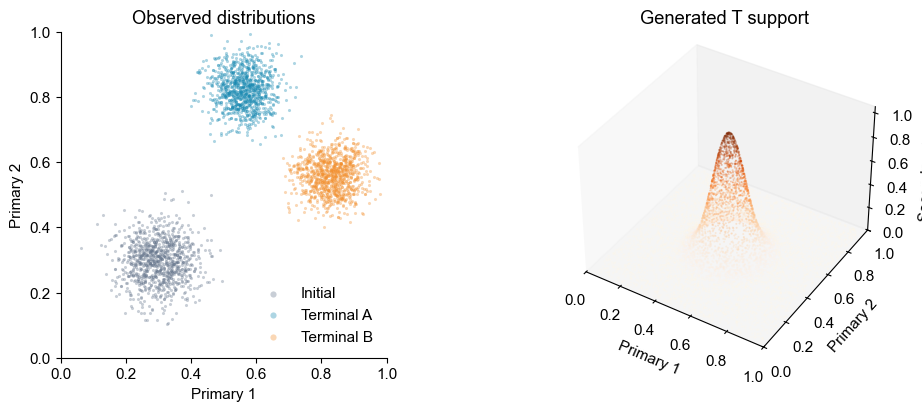

In [4]:
fig = plt.figure(figsize=(10, 4), layout="constrained")
ax = fig.add_subplot(1, 2, 1)
for label, color in zip(["Initial", "Terminal A", "Terminal B"], ["#64748b", "#1688b1", "#f28e2b"]):
    points = cells.obsm["X_latent"][cells.obs["celltype"] == label]
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=.35, color=color, linewidths=0, label=label)
ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="Primary 1", ylabel="Primary 2", title="Observed distributions")
ax.legend(frameon=False, markerscale=2)
ax.spines[["top", "right"]].set_visible(False)
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.scatter(support3d[:, 0], support3d[:, 1], support3d[:, 2], s=2,
            c=support3d[:, 2], cmap="Oranges", alpha=.3, linewidths=0)
ax3.set(xlim=(0, 1), ylim=(0, 1), zlim=(0, 1.05), title="Generated T support",
        xlabel="Primary 1", ylabel="Primary 2", zlabel="Secondary height")
ax3.view_init(elev=38, azim=-58)
ax3.grid(False)
plt.show()

## Train T first

Follow the original `train_bump_T.py`: FourierBumpMLP, 6000 AdamW steps,
batch 768, weighted MSE with z weight 12, and a seeded 85/15 training/validation
split over observed and support pairs. Keep the state with the lowest validation
loss, then freeze T. No grid evaluation is used for selecting that state.

In [5]:
T, map_history, map_fit = fit_bump_map(
    map_pairs, seed=0, steps=6000, batch_size=768, lr=1e-3, weight_decay=1e-5,
    val_fraction=.15, z_weight=12., observed_weight=1., support_weight=1.,
    hidden=160, n_layers=4, num_frequencies=10, max_frequency=18.,
    xy_residual_scale=.05, eval_every=500, progress_path=run_dir / "progress.json",
)
print("Best step:", map_fit["best_step"])
map_pairs.obs.groupby(["map_split", "source"], observed=True).size().rename("Pairs").to_frame()

T step    1/6000: validation loss=0.538956, z RMSE=0.211925


T step  500/6000: validation loss=0.00185662, z RMSE=0.0124386


T step 1000/6000: validation loss=0.00189851, z RMSE=0.0125781


T step 1500/6000: validation loss=0.00180481, z RMSE=0.0122638


T step 2000/6000: validation loss=0.00183992, z RMSE=0.0123825


T step 2500/6000: validation loss=0.00194275, z RMSE=0.0127238


... (5 outputs left out)

T step 5500/6000: validation loss=0.00190094, z RMSE=0.0125862


T step 6000/6000: validation loss=0.00191293, z RMSE=0.0126258


Best step: 1500


Pairs
map_split  source         
Training   Observed   2566
           Support    5934
Validation Observed    434
           Support    1066

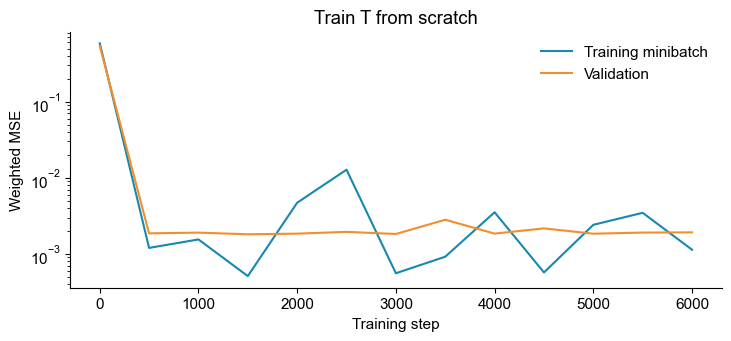

In [6]:
plot_map_training(map_history)
plt.show()

## Inspect T performance

Report held-out observed and support pairs separately. The independent 96 × 96
grid checks the learned surface against the known data-generating bump.
Only the learned T will be passed to synchronized trajectory training.

In [7]:
map_scores, map_grid = evaluate_bump_map(T, map_pairs, grid_n=96)
map_scores.round(6)

,Pairs,XY_RMSE,Z_RMSE,Z_MAE
Evaluation,,,,
Held-out observed,434,0.000047,0.021079,0.004067
Held-out support,1066,0.000065,0.005544,0.003500
Independent grid,9216,0.000067,0.005036,0.002998


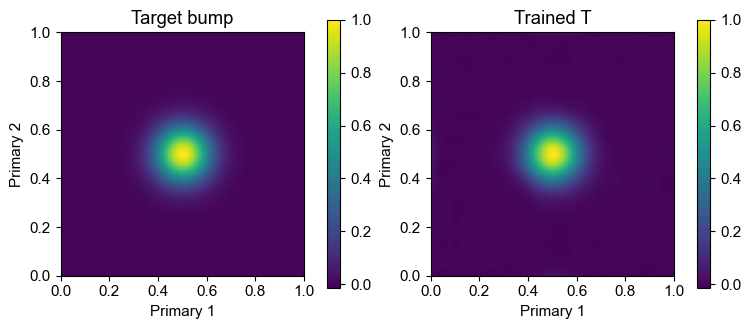

Grid z correlation: 0.999378
Learned height at (0.5, 0.5): 0.999919; target: 1


In [8]:
plot_map_performance(map_grid)
plt.show()
print(f"Grid z correlation: {map_grid['z_correlation']:.6f}")
print(f"Learned height at (0.5, 0.5): {map_grid['center_predicted_height']:.6f}; target: 1")
assert not any(parameter.requires_grad for parameter in T.parameters())

## Configure the flow comparison

Start from COATI defaults and override only this experiment's choices: 3000 steps,
batch 256, hidden width 256, balanced multimodal transport, adaptive Sinkhorn
penalties and Cy = 0.5. Both fields start from the same fresh seeded initialization,
with no warm-up or imported trajectory checkpoint.

In [9]:
config = ct.Config(
    multimodal=True,
    balanced=True,
    iterations=3000,
    batch_size=256,
    hidden_dim=256,
    secondary_weight=.5,
    extra={
        "time_plot": True,
        "median_n_sample": 512,
        "floor_n_sample": 256,
        "sync_density_loss": True,
        "map_type": "MLP",
        "adaptive_lambda": True,
    },
)
configs = {"Without sync": config.with_parameters(multimodal=False, secondary_weight=0.),
           "With sync": config}
pd.DataFrame({name: {key: cfg.to_dict()[key] for key in
    ["niters", "lr", "num_samples", "hidden_dim", "n_layers", "activation", "dt", "sync_loss", "sync_weight", "adaptive_lambda"]}
    for name, cfg in configs.items()})

,Without sync,With sync
niters,3000,3000
lr,0.001,0.001
num_samples,256,256
hidden_dim,256,256
n_layers,2,2
activation,leaky_relu,leaky_relu
dt,0.1,0.1
sync_loss,False,True
sync_weight,0.0,0.5
adaptive_lambda,True,True


## Train the two vector fields

The shared initialization below is generated in this run. Each fit uses only
`cells`; the support points enter through the already fitted and frozen T.

In [10]:
initial = make_shared_initial_checkpoint(config, run_dir / "initial.pt")
results = {}
for name, cfg in configs.items():
    print("Training:", name, flush=True)
    results[name] = ct.train_vector_field(
        cells, cfg, use_rep="X_latent", secondary_obsm_key="X_secondary",
        T_model=T if cfg.multimodal else None,
        output_dir=run_dir / ("with_sync" if cfg.multimodal else "without_sync"),
        warm_start_path=initial,
    )
    print(name, "completed", flush=True)

Training: Without sync


Without sync completed


Training: With sync


With sync completed


## Integrate and compare

Integrate the same initial population, then apply the trained T to both paths.
Draw all trajectories, with no path selection or smoothing.

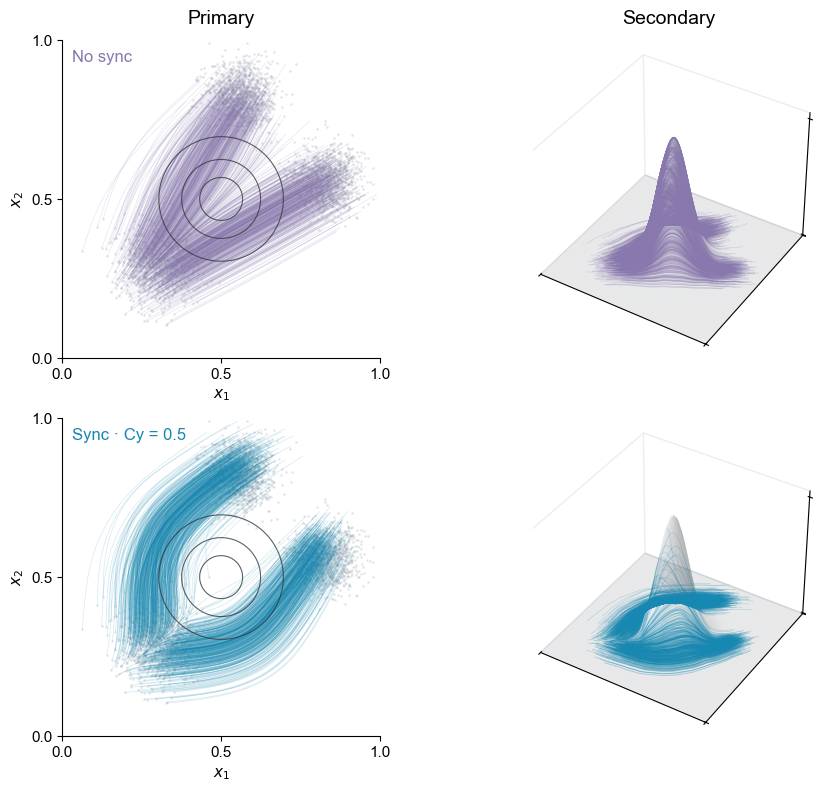

In [11]:
data = ct.TemporalData.from_anndata(cells, secondary_obsm_key="X_secondary")
predictions = {}
for name, result in results.items():
    prediction = result.predict_trajectory(times=np.linspace(0., 1., 51), method="rk4")
    with torch.no_grad():
        prediction["secondary"] = T(torch.tensor(prediction["primary"])).numpy()
    assert all(np.isfinite(value).all() for value in prediction.values())
    predictions[name] = prediction
plot_gaussian_sync(data, T, results, predictions)
plt.show()

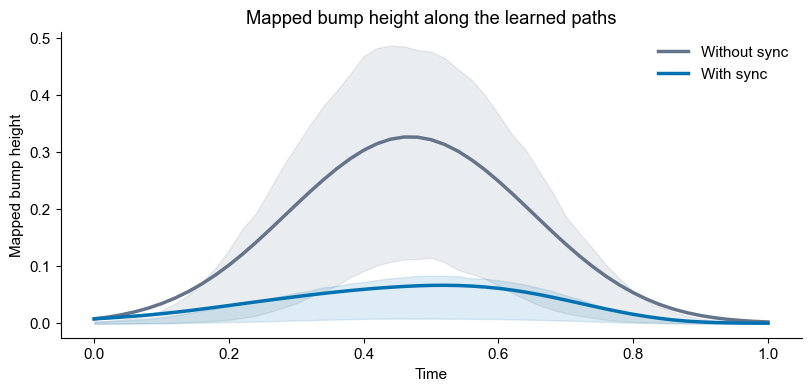

In [12]:
plot_bump_height(predictions)
plt.show()

## Check endpoint matching and energy

Balanced transport conserves total mass even though the sampled terminal snapshot
has twice as many cells. Interpret the learned paths together with endpoint fit
and the fitted-map diagnostics above.

In [13]:
scores = compare_gaussian_runs(results, predictions)
scores.T.round(6)

Model,Without sync,With sync
Primary endpoint Sinkhorn,0.000206,0.001425
Primary kinetic energy,0.161313,0.213448
Secondary kinetic energy,0.999115,0.266299
Predicted terminal mass,1.000000,1.000000
Target terminal mass,1.000000,1.000000
Median maximum bump height,0.380628,0.038393
States outside unit square,0.000000,0.000000
